<a href="https://colab.research.google.com/github/Fittx/Machine-Learning---CCMACLRL/blob/main/ML-GDG-Exercises/%5B05%5D_Pre_Trained_Models_and_Feature_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5. Pre-Trained Models and Feature Extraction

A neural network does not always have to learn everything from scratch. Large vision models are often trained on **ImageNet**, a dataset containing millions of images across 1,000 object categories. Their early and middle layers learn useful visual patterns such as edges, textures, shapes, and object parts.

In this module, we will load a model that has already been trained on ImageNet and use it to explore a **Sea Animals** image dataset. First, we will run the model as-is and discuss why its predictions may not match our dataset's labels. Then, we will inspect how a pre-trained network can act as a **feature extractor** for a new task.

This notebook introduces pre-trained models and inference. In the next module, we will adapt a pre-trained model to our own classes through transfer learning and fine-tuning.

---
### ✏️ How this notebook works
Most coding cells in this notebook come in a pair:

1. **📘 Worked Example:** a small, working demo of the *pattern* you'll need, in a different scenario from the real task. Run it first and read the comments.
2. **✏️ Fill-in-the-blank cell:** wherever you see a blank (`_____`), write the missing code yourself. The example shows the pattern, but you'll need to work out the exact answer using the section's explanation and the `Hint` comments.

Cells with a **✅ Check** at the bottom will tell you whether your answers are right. Run the cells in order from top to bottom. (Setup, data-download, exploration and display cells are already complete; just run them.)

## 5.1 Objectives

By the end of this module, you will be able to:

- Explain what a pre-trained model is and why **ImageNet** is commonly used
- Identify the role of a model's backbone and classification head
- Load an ImageNet-pretrained model from `torchvision`
- Prepare images using the preprocessing associated with the selected weights
- Run inference and interpret the model's top predictions
- Explain feature extraction and why pre-trained features can help with a new image-classification task

## 5.2 Environment Setup

This notebook is designed for Google Colab. A GPU is helpful, but the examples can also run on a CPU. If you use Colab, select **Runtime → Change runtime type → T4 GPU** if one is available.

In [1]:
# Install the dataset download helper
!pip install -q kagglehub

In [2]:
import os
import glob
import random
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
from torchvision.models import vgg16, VGG16_Weights

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cpu


## 5.3 The Dataset: Sea Animals

We will use the [Sea Animals Image Dataset on Kaggle](https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste). It contains images belonging to different sea-animal categories.

The dataset is downloaded with `kagglehub`. Its exact directory layout can vary, so the next cells inspect the downloaded folders instead of assuming that the images are in one fixed location.

In [3]:
import kagglehub

# Download the latest available version
DATA_PATH = kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste")
print("Path to dataset files:", DATA_PATH)

Using Colab cache for faster access to the 'sea-animals-image-dataste' dataset.
Path to dataset files: /kaggle/input/sea-animals-image-dataste


In [4]:
# Inspect the first few directory levels
for root, dirs, files in os.walk(DATA_PATH):
    level = root.replace(DATA_PATH, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        if level < 2:
            for filename in files[:5]:
                print("  " * (level + 1) + filename)

sea-animals-image-dataste/
  Penguin/
    13441017033_5f20afed5c_o.jpg
    6814743888_d76f64e5e5_o.jpg
    7678547704_88ee08ec1d_b.jpg
    8474798677_0abda01a4a_o.jpg
    32902414928_2e8353fa26_o.jpg
  Clams/
    11127770525_eb487e975c_b.jpg
    7409907104_e68910d92d_o.jpg
    24659170965_ed13a20e49_o.jpg
    134917699_add44eaf73_o.jpg
    11587746256_6d931eb556_o.jpg
  Lobster/
    10508592885_c5d0dd4d2f_o.jpg
    20185221740_205d8ed735_o.jpg
    7898780506_b487483356_o.jpg
    8598643346_f6182a055a_o.jpg
    7721952750_ba4c1bd1df_o.jpg
  Otter/
    1755682925_53f103f317_o.jpg
    5614180288_ac2acf34ac_o.jpg
    8499384131_73b24d4249_o.jpg
    20669564526_6369dfe34a_b.jpg
    2176081409_b32f1d31d5_o.jpg
  Eel/
    2040454766_d57e4af274_o.jpg
    4902891766_7d9371ed2b_b.jpg
    4292996536_262e3dcbd8_b.jpg
    14280703959_ef6e6d8ccb_o.jpg
    18800223795_244c681904_b.jpg
  Corals/
    7665815360_48b9c545fa_o.jpg
    20209147344_7dc3bffe22_o.jpg
    4609512390_dbeca733af_o.jpg
    202091

### Find the image-class folders

For `ImageFolder` to work, images should be organized into one subfolder per class. The helper below searches for a directory whose immediate subfolders contain images. If the printed result does not look like class folders, inspect the directory listing above and adjust `IMAGE_ROOT` manually.

In [5]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def contains_images(folder):
    return any(
        os.path.isfile(os.path.join(folder, name)) and name.lower().endswith(IMAGE_EXTENSIONS)
        for name in os.listdir(folder)
    )

def find_imagefolder_root(base_path):
    candidates = []
    for root, dirs, files in os.walk(base_path):
        class_dirs = [
            os.path.join(root, d) for d in dirs
            if os.path.isdir(os.path.join(root, d))
            and contains_images(os.path.join(root, d))
        ]
        if len(class_dirs) >= 2:
            candidates.append((root, len(class_dirs)))
    if not candidates:
        return None
    # Prefer a candidate with many immediate class folders, and then the shallower path.
    candidates.sort(key=lambda item: (-item[1], item[0].count(os.sep)))
    return candidates[0][0]

IMAGE_ROOT = find_imagefolder_root(DATA_PATH)
print("Suggested image-folder root:", IMAGE_ROOT)

Suggested image-folder root: /kaggle/input/sea-animals-image-dataste


In [6]:
# If the suggested root is not the folder containing one subfolder per animal class,
# replace IMAGE_ROOT with the correct path from the directory listing above.
if IMAGE_ROOT is None:
    raise FileNotFoundError(
        "Could not automatically find class folders. Inspect DATA_PATH and set IMAGE_ROOT manually."
    )

class_folders = sorted([
    name for name in os.listdir(IMAGE_ROOT)
    if os.path.isdir(os.path.join(IMAGE_ROOT, name))
    and contains_images(os.path.join(IMAGE_ROOT, name))
])
print(f"Found {len(class_folders)} class folders:")
for name in class_folders:
    count = sum(
        1 for f in os.listdir(os.path.join(IMAGE_ROOT, name))
        if f.lower().endswith(IMAGE_EXTENSIONS)
    )
    print(f"  {name}: {count} images")

Found 23 class folders:
  Clams: 497 images
  Corals: 500 images
  Crabs: 499 images
  Dolphin: 782 images
  Eel: 497 images
  Fish: 494 images
  Jelly Fish: 845 images
  Lobster: 499 images
  Nudibranchs: 500 images
  Octopus: 562 images
  Otter: 500 images
  Penguin: 482 images
  Puffers: 531 images
  Sea Rays: 517 images
  Sea Urchins: 579 images
  Seahorse: 478 images
  Seal: 414 images
  Sharks: 590 images
  Shrimp: 488 images
  Squid: 483 images
  Starfish: 499 images
  Turtle_Tortoise: 1903 images
  Whale: 572 images


## 5.4 Explore a Few Images

Before using a model, look at the data. Image dimensions, lighting, backgrounds, and image quality can affect predictions. The labels in the folder names describe the dataset's classes; they are not necessarily the same as ImageNet's 1,000 output categories.

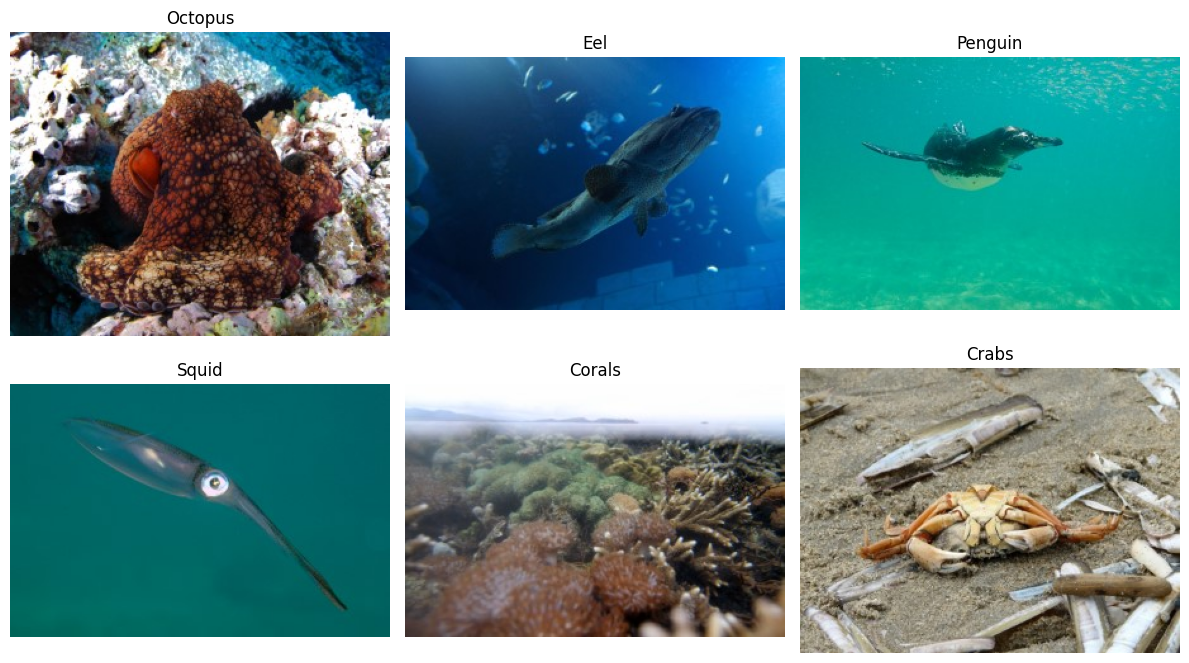

In [7]:
# Display a few sample images from the dataset
image_paths = []
for class_name in class_folders:
    folder = os.path.join(IMAGE_ROOT, class_name)
    for filename in os.listdir(folder):
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            image_paths.append((os.path.join(folder, filename), class_name))

random.seed(7)
samples = random.sample(image_paths, min(6, len(image_paths)))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, (path, label) in zip(axes.flat, samples):
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(label)
plt.tight_layout()
plt.show()

## 5.5 ImageNet and Pre-Trained Models

**ImageNet** is a large image dataset commonly used to train and evaluate image-recognition models. The VGG16 model provided by `torchvision` can be loaded with weights that were trained on ImageNet.

A typical image-classification model has two conceptual parts:

- **Backbone / feature extractor:** learns visual representations from pixels, such as edges, textures, patterns, and shapes.
- **Classification head:** converts those representations into scores for a fixed set of classes.

VGG16's ImageNet classifier produces scores for **1,000 ImageNet categories**. Our sea-animal dataset has its own folder labels, so the output categories will not automatically match those labels.

### Load VGG16 with ImageNet weights

We will use the recommended preprocessing attached to the selected weights. This resizes and normalizes the image in the way expected by the pre-trained model. Using the matching preprocessing is important: feeding a model images in an unexpected format or scale can reduce prediction quality.

In [8]:
# 📘 WORKED EXAMPLE (run me first!): loading a different pre-trained model
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

# Pick one specific, named set of ImageNet weights
small_weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1

# Build the architecture and load those weights into it, then put it in prediction mode
small_model = mobilenet_v3_small(weights=small_weights)
small_model.eval()

# The weights object also carries the matching preprocessing, plus a dictionary of metadata
small_preprocess = small_weights.transforms()
print("Preprocessing:", small_preprocess)
print("Metadata keys:", list(small_weights.meta.keys()))
print("Number of parameters:", small_weights.meta["num_params"])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 134MB/s]

Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Metadata keys: ['min_size', 'categories', 'num_params', 'recipe', '_metrics', '_ops', '_file_size', '_docs']
Number of parameters: 2542856


In [10]:
# ✏️ YOUR TURN
# Tip: in Colab, type `VGG16_Weights.` and press Tab to see which weight options exist.
weights = VGG16_Weights.IMAGENET1K_V1                       # (1/5) the recommended ImageNet weights
model = vgg16(weights=True).to(device)             # (2/5) build VGG16 and load those weights
model.eval()                                          # (3/5) prediction mode

# Preprocessing recommended for these ImageNet weights
preprocess = weights.transforms()                      # (4/5) the weights object knows its own preprocessing

# The 1,000 category names used by the pretrained classifier
# (5/5) Look at the "Metadata keys" printed in the worked example: which key holds the names?
imagenet_categories = weights.meta["categories"]

print("Number of ImageNet categories:", len(imagenet_categories))
print("Example categories:", imagenet_categories[:10])

# ✅ Check: run this to see if your answers are right
assert len(imagenet_categories) == 1000, "VGG16 predicts 1,000 ImageNet categories"
assert not model.training, "The model should be in prediction (eval) mode"
print("Correct!")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 76.8MB/s]


Number of ImageNet categories: 1000
Example categories: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich']
Correct!


## 5.6 Run Inference on a Sea-Animal Image

**Inference** means using a trained model to make a prediction. We do not update the model's weights in this section.

The model will choose from its original ImageNet categories. It might recognize something visually related to a sea animal, or it might choose a surprising category. That does not necessarily mean the model is broken: it has not been trained specifically on the class labels in our dataset.

In [11]:
# 📘 WORKED EXAMPLE (run me first!): the steps of inference, by hand
import torch

# 1) One image has shape (channels, height, width). Models expect a BATCH: (batch, channels, height, width).
demo_image = torch.rand(3, 8, 8)
demo_batch = demo_image[None]            # None adds a new axis of size 1 at that position
print("Single:", tuple(demo_image.shape), "-> Batch:", tuple(demo_batch.shape))

# 2) A model's output for a batch has one ROW per image. Here: 1 image, 6 made-up categories.
demo_logits = torch.tensor([[2.0, 0.5, 1.0, 3.5, -1.0, 0.0]])
print("Logits shape:", tuple(demo_logits.shape))

# 3) Turn scores into probabilities that add up to 1. `dim` is the axis the probabilities must sum over.
demo_probs = torch.softmax(demo_logits, dim=1)
print("Each row sums to:", demo_probs.sum(dim=1).item())

# 4) Rank the categories from best to worst, and keep the best three of the first (only) row
demo_sorted_probs, demo_sorted_idx = torch.sort(demo_probs[0], descending=True)
print("Top-3 category numbers:", demo_sorted_idx[:3].tolist())
print("Top-3 probabilities:", [round(p, 3) for p in demo_sorted_probs[:3].tolist()])

# 5) When only predicting, we can skip gradient bookkeeping to save memory and time
with torch.inference_mode():
    demo_result = demo_logits * 2
print("Is this result tracking gradients?", demo_result.requires_grad)

Single: (3, 8, 8) -> Batch: (1, 3, 8, 8)
Logits shape: (1, 6)
Each row sums to: 1.0
Top-3 category numbers: [3, 0, 2]
Top-3 probabilities: [0.716, 0.16, 0.059]
Is this result tracking gradients? False


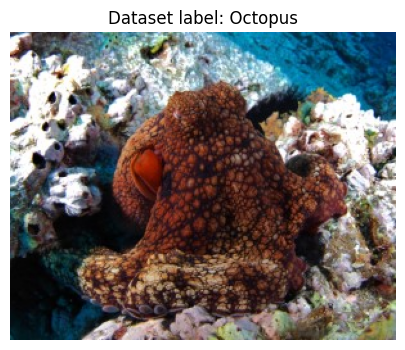

Top 5 ImageNet predictions:
coral reef: 58.42%
anemone fish: 18.04%
brain coral: 12.56%
rock beauty: 4.78%
sea cucumber: 1.25%
Correct!


In [16]:
# Select one image and display it
sample_path, sample_label = samples[0]
with Image.open(sample_path) as image:
    display_image = image.convert("RGB")
    # ✏️ (1/5) Preprocess, then add a batch axis at the front so the shape becomes (1, 3, H, W)
    input_tensor = preprocess(display_image)[None].to(device)

plt.figure(figsize=(5, 4))
plt.imshow(display_image)
plt.title(f"Dataset label: {sample_label}")
plt.axis("off")
plt.show()

# Run inference without calculating gradients
with torch.no_grad():                                     # (2/5) the classic "no gradients" context manager
    logits = model(input_tensor)                          # (3/5) feed in the prepared image
    # (4/5) logits[0] is a flat list of 1,000 scores. How many axes does a flat list have?
    probabilities = torch.softmax(logits[0], dim=0)

# (5/5) Keep the 5 most likely categories (the worked example sorted everything; PyTorch has a shortcut for the best k)
top_probs, top_indices = torch.topk(probabilities, k=5)
print("Top 5 ImageNet predictions:")
for probability, index in zip(top_probs.cpu().tolist(), top_indices.cpu().tolist()):
    print(f"{imagenet_categories[index]}: {probability:.2%}")

# ✅ Check: run this to see if your answers are right
assert input_tensor.shape == (1, 3, 224, 224), "The input should be a batch of one 224x224 RGB image"
assert abs(probabilities.sum().item() - 1.0) < 1e-4, "Probabilities should add up to 1 (check the dim)"
assert top_indices.numel() == 5, "We want the top 5 predictions"
print("Correct!")

### Discussion

1. Does the top prediction match the sea-animal folder label?
2. Are any of the top-five predictions related to the image?
3. Why might a model trained on ImageNet not recognize the exact classes used in our dataset?

Remember: these are predictions among ImageNet's original labels. We have not trained this model on the sea-animal labels yet.

## 5.7 What Does Feature Extraction Mean?

When an image passes through VGG16, its convolutional layers transform the raw pixels into a collection of learned visual features. Rather than starting with random weights, we can reuse those features for a new task.

In **feature extraction**, we generally:

1. Load a model pre-trained on a large dataset such as ImageNet.
2. Keep its learned backbone fixed (freeze its parameters).
3. Replace the original classifier with a new classifier sized for our own classes.
4. Train the new classifier using images from our dataset.

The backbone provides a useful starting point, while the new head learns how to map its features to our sea-animal categories. This differs from **fine-tuning**, where some or all of the pre-trained backbone is also allowed to update during training.

### Inspect the VGG16 architecture

Run the next cell and look at the two main components: `features` and `classifier`. The `features` component contains convolution and pooling operations. The classifier at the end was originally designed to predict ImageNet's 1,000 classes.

In [17]:
print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

### A peek at the extracted features

The following cell uses only VGG16's convolutional feature extractor. The resulting tensor is a numerical representation of the image—not a class prediction. We will not train a new classifier in this module; that is the focus of the next module.

In [18]:
# 📘 WORKED EXAMPLE (run me first!): running only ONE part of a model
import torch
import torch.nn as nn

class DemoNet(nn.Module):
    def __init__(self):
        super().__init__()
        # The model's parts are stored under names, so we can reach them as attributes
        self.encoder = nn.Sequential(nn.Conv2d(3, 6, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Linear(6 * 4 * 4, 2)

    def forward(self, x):
        return self.head(self.encoder(x).flatten(1))

demo_net = DemoNet()
demo_input = torch.rand(1, 3, 8, 8)

with torch.no_grad():
    demo_codes = demo_net.encoder(demo_input)    # only the first part (a sub-module is called like a function too)
    demo_final = demo_net(demo_input)            # the whole model

print("Encoder output shape:", tuple(demo_codes.shape))   # a feature map, not class scores
print("Full model output shape:", tuple(demo_final.shape))
print("Names of the model's parts:", [name for name, _ in demo_net.named_children()])

Encoder output shape: (1, 6, 4, 4)
Full model output shape: (1, 2)
Names of the model's parts: ['encoder', 'head']


In [20]:
# ✏️ YOUR TURN
# Run ONLY the convolutional part of VGG16. Look at the printed architecture above:
# what is the name of the component that holds the convolution and pooling layers?
with torch.no_grad():
    feature_map = model.features(input_tensor)

print("Input tensor shape:", tuple(input_tensor.shape))
print("Feature-map shape:", tuple(feature_map.shape))

# ✅ Check: run this to see if your answers are right
assert feature_map.shape[1] == 512 and feature_map.shape[2:] == (7, 7), "VGG16's feature extractor outputs 512 channels of 7x7"
print("Correct!")

Input tensor shape: (1, 3, 224, 224)
Feature-map shape: (1, 512, 7, 7)
Correct!


## 5.8 Knowledge Check

Try answering these before continuing:

1. What does it mean for a model to be *pre-trained*?
2. What is ImageNet, and how many categories does this VGG16 classifier predict?
3. What is the difference between a backbone and a classification head?
4. Why might the model's ImageNet prediction not match the sea-animal dataset label?
5. In feature extraction, which part of the model is typically frozen, and which part is trained?
6. How does fine-tuning differ from feature extraction?

## 5.9 Summary

In this module, you:

- Downloaded and explored the Sea Animals image dataset
- Loaded VGG16 with pre-trained ImageNet weights
- Used the matching preprocessing pipeline to run inference
- Examined the model's top ImageNet predictions and discussed why labels may not match our dataset
- Inspected the backbone's feature maps and learned the idea behind feature extraction

A pre-trained model gives us a useful starting point, but it does not automatically know our custom labels. In the next module, **Transfer Learning and Fine-Tuning**, we will replace the classifier head and train the model for a dataset-specific task.

### Clear the Memory

After you finish the notebook, you may run the cell below to release GPU memory before moving to the next module.

In [21]:
# Uncomment these lines if you want to restart the Colab runtime:
# import IPython
# IPython.Application.instance().kernel.do_shutdown(True)

## References